# 02C · Hoàng Công Lý – Q5
*Tuổi, khoảng thu nhập và sự khác biệt giữa các nhóm người dùng.*

> Q6 Machine Learning nằm trong `03_ml_question.ipynb`.

In [1]:
# Thiết lập đường dẫn (chạy Jupyter từ repo root hoặc thư mục notebooks đều được)
from pathlib import Path
import sys
ROOT = Path.cwd().resolve()
if ROOT.name == "notebooks":
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT / "src"))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from coupon_project.data_io import load_raw_data, row_count_log
from coupon_project.quality import missing_table

df = load_raw_data(ROOT / "data" / "raw" / "in-vehicle-coupon-recommendation.csv")
print(f"Raw data: {df.shape[0]:,} rows x {df.shape[1]} columns")

Raw data: 12,684 rows x 26 columns


### Yêu cầu chung cho MỖI câu hỏi

1. Viết motivation và ai quan tâm đến câu hỏi.
2. Mô tả preprocessing bằng Markdown, nêu row counts trước/sau mọi thao tác filter, drop, merge.
3. Mô tả phương pháp và tại sao hợp lý; thực hiện các D tiêu chí đã đăng ký.
4. Có ít nhất **2 biểu đồ** có tiêu đề, trục, đơn vị, chú giải khi cần.
5. Trả lời bằng **con số thực**, uncertainty nếu thuộc D5, nêu giới hạn và ý nghĩa.

In [2]:
# Cấu hình chung cho notebook Q5
SEED = 42        # cố định hạt giống ngẫu nhiên để chạy lại ra đúng cùng kết quả
N_BOOT = 2000    # số lần lặp bootstrap cho mỗi khoảng tin cậy

# Ghi lại phiên bản thư viện để người khác chạy lại và đối chiếu được
import matplotlib
print(f"Python {sys.version.split()[0]} | numpy {np.__version__} | pandas {pd.__version__} | matplotlib {matplotlib.__version__}")

FIG_DIR = ROOT / "reports" / "figures"
FIG_DIR.mkdir(parents=True, exist_ok=True)

pd.set_option("display.max_columns", 30)
pd.set_option("display.width", 160)
plt.rcParams.update({
    "figure.dpi": 110,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.grid": True,
    "grid.color": "#e6e5e1",
    "grid.linewidth": 0.8,
    "axes.axisbelow": True,
})

Python 3.11.16 | numpy 2.4.6 | pandas 3.0.6 | matplotlib 3.11.2


## Q5 · Tuổi và thu nhập liên quan đến việc chấp nhận coupon ra sao sau khi xét thói quen?
**Owner:** Hoàng Công Lý
**Cột sử dụng:** `age, income, coupon, Bar, CoffeeHouse, CarryAway, RestaurantLessThan20, Restaurant20To50, Y` (và các cột hồ sơ cá nhân để dựng mã người trả lời giả định).
**Tiêu chí độ sâu:** **D4** (kiểm soát biến nhiễu), **D5** (định lượng bất định), **D6** (kiểm tra độ bền).

**Câu hỏi.** Mối liên hệ giữa nhóm tuổi, khoảng thu nhập và tỷ lệ chấp nhận coupon có còn quan sát thấy sau khi so sánh **trong cùng loại coupon** và **cùng mức thói quen** đến loại địa điểm tương ứng hay không?

**Motivation.** Một đội marketing của ứng dụng gợi ý ưu đãi trên xe thường phân khúc khách hàng theo nhân khẩu học vì tuổi và thu nhập là thông tin dễ có nhất. Nhưng nếu người trẻ nhận coupon nhiều hơn chỉ vì họ *hay đi bar, hay uống cà phê hơn*, thì thứ cần dùng để nhắm ưu đãi là **thói quen**, không phải tuổi. Câu hỏi này giúp trả lời: nên ưu tiên phân khúc theo tuổi/thu nhập, hay theo thói quen, hay cả hai?

**Ai quan tâm:** người thiết kế chiến dịch coupon (chọn tiêu chí nhắm khách), và nhóm làm mô hình ở Q6 (biết trước biến nào có khả năng mang tín hiệu).

**Lưu ý diễn giải.** `Y` là *ý định* chấp nhận trong kịch bản khảo sát, không phải giao dịch thật. Mọi kết quả dưới đây là **mối liên hệ quan sát được**, không phải quan hệ nhân quả.

### Q5.1 · Dữ liệu dùng cho Q5 và kiểm tra chất lượng

Các bước tiền xử lý (mô tả trước, code ngay bên dưới):

1. **Xem nhãn thật** của `age`, `income`, `coupon` và tỷ lệ thiếu ở các cột liên quan. `age` có nhãn chữ (`below21`, `50plus`) và `income` là khoảng tiền, nên cả hai được giữ ở dạng **phân loại có thứ tự**, không ép sang số.
2. **Dựng mã người trả lời giả định** `respondent_id`. Bộ dữ liệu không có ID người trả lời, nhưng mỗi người trả lời nhiều kịch bản và các cột hồ sơ cá nhân (giới tính, tuổi, hôn nhân, con cái, học vấn, nghề, thu nhập, xe, 5 cột thói quen) giống hệt nhau trên mọi dòng của cùng một người. Các dòng trùng toàn bộ hồ sơ được coi là cùng một người. Việc này quan trọng vì tuổi và thu nhập là thuộc tính **của người**, không phải của dòng: 22 dòng của một người không phải 22 quan sát độc lập.
3. **Gộp nhóm tuổi và thu nhập** để mỗi ô `nhóm × coupon` có đủ mẫu (cách gộp khác được thử lại ở phần D6).
4. **Tạo `matched_frequency`**: với mỗi dòng, lấy tần suất ở cột thói quen *khớp với loại coupon của dòng đó* (coupon `Bar` → cột `Bar`, coupon `Coffee House` → cột `CoffeeHouse`, …), rồi chia thành hai mức: đến **ít** (dưới 1 lần/tháng) và đến **thường** (từ 1 lần/tháng trở lên).
5. **Không xoá dòng nào khỏi dữ liệu chính.** Riêng các phép so sánh có kiểm soát thói quen cần biết `matched_frequency`, nên dùng một bản con đã bỏ các dòng thiếu giá trị này; số dòng trước/sau được in ra.

In [3]:
# Bước 1: xem nhãn thật trong CSV trước khi viết bất kỳ mapping nào
HABIT_COLS = ["Bar", "CoffeeHouse", "CarryAway", "RestaurantLessThan20", "Restaurant20To50"]
Q5_COLS = ["age", "income", "coupon"] + HABIT_COLS + ["Y"]

for col in ["age", "income", "coupon"]:
    print(f"\n{col}: {df[col].nunique()} nhãn khác nhau")
    print(df[col].value_counts(dropna=False).to_string())

print("\nThiếu dữ liệu ở các cột dùng cho Q5:")
display(missing_table(df[Q5_COLS]))


age: 8 nhãn khác nhau
age
21         2653
26         2559
31         2039
50plus     1788
36         1319
41         1093
46          686
below21     547

income: 9 nhãn khác nhau
income
$25000 - $37499     2013
$12500 - $24999     1831
$37500 - $49999     1805
$100000 or More     1736
$50000 - $62499     1659
Less than $12500    1042
$87500 - $99999      895
$75000 - $87499      857
$62500 - $74999      846

coupon: 5 nhãn khác nhau
coupon
Coffee House             3996
Restaurant(<20)          2786
Carry out & Take away    2393
Bar                      2017
Restaurant(20-50)        1492

Thiếu dữ liệu ở các cột dùng cho Q5:


,missing_count,missing_pct
CoffeeHouse,217,1.71
Restaurant20To50,189,1.49
CarryAway,151,1.19
RestaurantLessThan20,130,1.02
Bar,107,0.84
age,0,0.00
income,0,0.00
coupon,0,0.00
Y,0,0.00


In [4]:
# Bước 2: dựng mã người trả lời giả định từ các cột hồ sơ cá nhân
PROFILE_COLS = ["gender", "age", "maritalStatus", "has_children", "education",
                "occupation", "income", "car"] + HABIT_COLS

q5 = df[Q5_COLS].copy()   # bản làm việc riêng của Q5; df gốc không bị sửa
# ngroup() đánh số 0, 1, 2, ... cho từng tổ hợp hồ sơ khác nhau; dropna=False để NaN cũng là một giá trị hợp lệ
q5["respondent_id"] = df.groupby(PROFILE_COLS, dropna=False, sort=False).ngroup()

rows_per_person = q5["respondent_id"].value_counts()
print(f"Số hồ sơ khác nhau (người trả lời giả định): {rows_per_person.size}")
print(f"Số dòng mỗi hồ sơ: trung vị {rows_per_person.median():.0f}, "
      f"nhỏ nhất {rows_per_person.min()}, lớn nhất {rows_per_person.max()}")
print(f"Tỷ lệ hồ sơ có đúng 22 dòng: {(rows_per_person == 22).mean():.1%}")

Số hồ sơ khác nhau (người trả lời giả định): 567
Số dòng mỗi hồ sơ: trung vị 22, nhỏ nhất 6, lớn nhất 110
Tỷ lệ hồ sơ có đúng 22 dòng: 86.2%


Phần lớn hồ sơ có đúng 22 dòng, khớp với thiết kế khảo sát (mỗi người trả lời khoảng 20 kịch bản). Điều này ủng hộ cách dựng `respondent_id`. Hạn chế: hai người khác nhau có hồ sơ trùng hoàn toàn sẽ bị gộp thành một (các hồ sơ có 44, 66, 110 dòng nhiều khả năng là trường hợp này). Việc gộp nhầm như vậy chỉ làm khoảng tin cậy rộng hơn một chút chứ không làm nó hẹp giả tạo.

In [5]:
# Bước 3: giữ age/income ở dạng phân loại có thứ tự, rồi gộp nhóm
AGE_ORDER = ["below21", "21", "26", "31", "36", "41", "46", "50plus"]
INCOME_ORDER = ["Less than $12500", "$12500 - $24999", "$25000 - $37499",
                "$37500 - $49999", "$50000 - $62499", "$62500 - $74999",
                "$75000 - $87499", "$87500 - $99999", "$100000 or More"]
# Nhãn ngắn để hiển thị trên biểu đồ (đơn vị: nghìn USD, viết tắt k)
INCOME_SHORT = ["<12.5k", "12.5–25k", "25–37.5k", "37.5–50k", "50–62.5k",
                "62.5–75k", "75–87.5k", "87.5–100k", "≥100k"]

# Dừng ngay nếu CSV có nhãn lạ, để không âm thầm tạo NaN khi gộp nhóm
assert set(df["age"].unique()) == set(AGE_ORDER)
assert set(df["income"].unique()) == set(INCOME_ORDER)

q5["age"] = pd.Categorical(q5["age"], categories=AGE_ORDER, ordered=True)
q5["income"] = pd.Categorical(q5["income"], categories=INCOME_ORDER, ordered=True)


def regroup(series, mapping, order):
    """Gộp nhãn gốc thành nhóm lớn hơn theo `mapping`, giữ thứ tự nhóm trong `order`."""
    return pd.Categorical(series.astype(str).map(mapping), categories=order, ordered=True)


# Nhãn tuổi trong khảo sát là mốc dưới của khoảng 5 năm: "21" = 21–25, "26" = 26–30, ..., "46" = 46–50
AGE_GROUPS = ["<26", "26–35", "36–50", "50+"]
AGE_GROUP_MAP = {"below21": "<26", "21": "<26",
                 "26": "26–35", "31": "26–35",
                 "36": "36–50", "41": "36–50", "46": "36–50",
                 "50plus": "50+"}

INCOME_GROUPS = ["Thấp (<37.5k)", "Trung bình (37.5k–<75k)", "Cao (≥75k)"]
INCOME_GROUP_MAP = dict(zip(INCOME_ORDER, ["Thấp (<37.5k)"] * 3 + ["Trung bình (37.5k–<75k)"] * 3 + ["Cao (≥75k)"] * 3))

q5["age_group"] = regroup(q5["age"], AGE_GROUP_MAP, AGE_GROUPS)
q5["income_group"] = regroup(q5["income"], INCOME_GROUP_MAP, INCOME_GROUPS)

for group_col in ["age_group", "income_group"]:
    summary = q5.groupby(group_col, observed=True).agg(
        so_dong=("Y", "size"),
        so_nguoi=("respondent_id", "nunique"),
    )
    display(summary)

,so_dong,so_nguoi
age_group,,
<26,3200,143
26–35,4598,204
36–50,3098,136
50+,1788,84


,so_dong,so_nguoi
income_group,,
Thấp (<37.5k),4886,221
Trung bình (37.5k–<75k),4310,195
Cao (≥75k),3488,151


**Lý do gộp nhóm.** Nhóm `below21` chỉ có 547 dòng (24 người) và `46` chỉ có 686 dòng (29 người); nếu chia tiếp theo 5 loại coupon và 2 mức thói quen thì nhiều ô chỉ còn vài người. Gộp thành 4 nhóm tuổi và 3 nhóm thu nhập giúp mỗi nhóm có ít nhất 84 người. Ranh giới thu nhập được đặt ở 37.500 và 75.000 USD để ba nhóm có số dòng gần nhau.

In [6]:
# Bước 4: tần suất thói quen khớp với loại coupon của từng dòng
COUPON_TO_HABIT = {
    "Coffee House": "CoffeeHouse",
    "Bar": "Bar",
    "Carry out & Take away": "CarryAway",
    "Restaurant(<20)": "RestaurantLessThan20",
    "Restaurant(20-50)": "Restaurant20To50",
}
COUPON_ORDER = list(COUPON_TO_HABIT)   # thứ tự cột cố định cho mọi bảng và biểu đồ
assert set(q5["coupon"].unique()) == set(COUPON_TO_HABIT)

q5["matched_frequency"] = pd.Series(np.nan, index=q5.index, dtype="object")
for coupon_name, habit_col in COUPON_TO_HABIT.items():
    is_this_coupon = q5["coupon"] == coupon_name
    q5.loc[is_this_coupon, "matched_frequency"] = q5.loc[is_this_coupon, habit_col]

# Hai mức thói quen. Ngưỡng chính: từ 1 lần/tháng trở lên là "Thường"
HABIT_LEVELS = ["Ít (<1 lần/tháng)", "Thường (≥1 lần/tháng)"]
FREQUENT_MAP = {"never": HABIT_LEVELS[0], "less1": HABIT_LEVELS[0],
                "1~3": HABIT_LEVELS[1], "4~8": HABIT_LEVELS[1], "gt8": HABIT_LEVELS[1]}
# Ngưỡng thay thế (dùng ở D6): từ 4 lần/tháng trở lên mới là "Thường"
HABIT_LEVELS_ALT = ["Ít (<4 lần/tháng)", "Thường (≥4 lần/tháng)"]
FREQUENT_MAP_ALT = {"never": HABIT_LEVELS_ALT[0], "less1": HABIT_LEVELS_ALT[0], "1~3": HABIT_LEVELS_ALT[0],
                    "4~8": HABIT_LEVELS_ALT[1], "gt8": HABIT_LEVELS_ALT[1]}

# .map() giữ nguyên NaN: dòng thiếu tần suất KHÔNG bị coi là "never"
q5["frequent_user"] = pd.Categorical(q5["matched_frequency"].map(FREQUENT_MAP), categories=HABIT_LEVELS, ordered=True)
q5["frequent_user_alt"] = pd.Categorical(q5["matched_frequency"].map(FREQUENT_MAP_ALT), categories=HABIT_LEVELS_ALT, ordered=True)

print("matched_frequency (tính cả NaN):")
print(q5["matched_frequency"].value_counts(dropna=False).to_string())

matched_frequency (tính cả NaN):
matched_frequency
1~3      3843
less1    3192
4~8      2399
never    2073
gt8      1013
NaN       164


In [7]:
# Bước 5: bản con cho các phân tích có kiểm soát thói quen (bỏ dòng thiếu matched_frequency)
n_before = len(q5)
q5_cc = q5.dropna(subset=["matched_frequency"]).copy()
print(row_count_log(n_before, len(q5_cc), "Bỏ dòng thiếu matched_frequency"))
print(f"Tỷ lệ dòng bị bỏ: {(n_before - len(q5_cc)) / n_before:.2%}")
print(f"Số người còn lại: {q5_cc['respondent_id'].nunique()} / {q5['respondent_id'].nunique()}")

# Dòng thiếu có dồn vào một nhóm tuổi/thu nhập nào không?
q5["missing_habit"] = q5["matched_frequency"].isna()
for group_col in ["age_group", "income_group", "coupon"]:
    pct_missing = q5.groupby(group_col, observed=True)["missing_habit"].mean().mul(100).round(2)
    print(f"\n% dòng thiếu matched_frequency theo {group_col}:")
    print(pct_missing.to_string())

Bỏ dòng thiếu matched_frequency: 12,684 -> 12,520 rows (delta -164)
Tỷ lệ dòng bị bỏ: 1.29%
Số người còn lại: 560 / 567

% dòng thiếu matched_frequency theo age_group:
age_group
<26      1.03
26–35    1.72
36–50    1.03
50+      1.12

% dòng thiếu matched_frequency theo income_group:
income_group
Thấp (<37.5k)              1.23
Trung bình (37.5k–<75k)    1.23
Cao (≥75k)                 1.46

% dòng thiếu matched_frequency theo coupon:
coupon
Bar                      1.04
Carry out & Take away    0.92
Coffee House             1.80
Restaurant(20-50)        1.47
Restaurant(<20)          0.97


Chỉ 164 dòng (1,29%) thiếu `matched_frequency`, và không nhóm nào thiếu quá vài phần trăm. Dữ liệu chính `q5` vẫn giữ đủ **12.684 dòng**; bản `q5_cc` (**12.520 dòng**) chỉ dùng khi cần so sánh trong cùng mức thói quen. Dòng thiếu không được đổi thành `never` vì "không trả lời" khác với "không bao giờ đến".

### Q5.2 · Phương pháp

**Chỉ số.** Tỷ lệ chấp nhận của một nhóm = `mean(Y)` trong nhóm, tính theo %, luôn đi kèm số dòng `n` và số người.

**D4 – kiểm soát biến nhiễu, làm theo ba mức:**

1. **Thô:** so sánh tỷ lệ chấp nhận giữa các nhóm tuổi (hoặc thu nhập) trên toàn bộ dữ liệu.
2. **Trong cùng loại coupon:** lập bảng `nhóm × coupon`.
3. **Trong cùng loại coupon và cùng mức thói quen:** lập bảng `nhóm × coupon × frequent_user`.

Để gom nhiều tầng về một con số so sánh được, dùng **chuẩn hoá trực tiếp** (direct standardization): tính tỷ lệ chấp nhận của từng nhóm trong từng tầng (ví dụ tầng "coupon Bar, đến bar thường"), rồi lấy trung bình có trọng số, trong đó trọng số của mỗi tầng là **tỷ trọng của tầng đó trong toàn mẫu** và *giống nhau cho mọi nhóm*. Kết quả trả lời câu hỏi: "nếu các nhóm tuổi có cùng cơ cấu coupon và thói quen như toàn mẫu thì tỷ lệ chấp nhận của họ là bao nhiêu?". Phần chênh lệch còn lại sau chuẩn hoá là phần **không** giải thích được bằng coupon và thói quen.

**D5 – định lượng bất định.** Khoảng tin cậy 95% bằng **bootstrap theo người trả lời** (cluster bootstrap): mỗi lần lặp rút ngẫu nhiên có hoàn lại 567 người, người nào được rút thì lấy toàn bộ các dòng của người đó, rồi tính lại thống kê. Lặp 2.000 lần, lấy phân vị 2,5% và 97,5%. Rút theo người thay vì theo dòng vì tuổi/thu nhập là thuộc tính của người và các dòng của cùng một người có tương quan với nhau.

*Chi tiết cài đặt:* rút một người `k` lần tương đương với việc nhân mọi dòng của người đó với trọng số `k`. Vì vậy code không nhân bản DataFrame mà chỉ sinh vector trọng số rồi tính tỷ lệ có trọng số bằng `np.bincount`, nhanh hơn nhiều.

**D6 – độ bền.** Lặp lại so sánh chính với (a) hai cách gộp tuổi khác, (b) hai cách gộp thu nhập khác, (c) ngưỡng "đến thường" khác (≥4 lần/tháng), (d) bootstrap theo dòng thay vì theo người.

In [8]:
# Các hàm dùng chung cho D4, D5, D6

def rate_table(data, group_cols):
    """Bảng mô tả: số dòng, số người, số lần chấp nhận và tỷ lệ chấp nhận (%) theo nhóm."""
    table = data.groupby(group_cols, observed=True).agg(
        n=("Y", "size"),
        so_nguoi=("respondent_id", "nunique"),
        chap_nhan=("Y", "sum"),
        ty_le_pct=("Y", "mean"),
    )
    table["ty_le_pct"] = table["ty_le_pct"].mul(100).round(1)
    return table


def make_rate_fn(data, group_col, strata_cols=()):
    """Trả về hàm fn(w) tính tỷ lệ chấp nhận (%) của từng nhóm trong `group_col`.

    w là trọng số của từng dòng. Nếu `strata_cols` rỗng, kết quả là tỷ lệ thô.
    Nếu có `strata_cols`, kết quả là tỷ lệ chuẩn hoá trực tiếp: trung bình các
    tỷ lệ theo tầng, trọng số là tỷ trọng của từng tầng trong toàn bộ `data`.
    """
    group_code = data[group_col].cat.codes.to_numpy()          # 0, 1, 2, ... theo thứ tự nhóm
    n_groups = len(data[group_col].cat.categories)
    if strata_cols:
        stratum_code = data.groupby(list(strata_cols), observed=True).ngroup().to_numpy()
    else:
        stratum_code = np.zeros(len(data), dtype=int)          # chỉ có một tầng duy nhất
    assert (group_code >= 0).all() and (stratum_code >= 0).all(), "Còn NaN trong cột nhóm/tầng"
    n_strata = stratum_code.max() + 1
    y = data["Y"].to_numpy()
    cell_code = group_code * n_strata + stratum_code           # mã riêng cho từng ô (nhóm, tầng)
    n_cells = n_groups * n_strata

    def fn(w):
        accepted = np.bincount(cell_code, weights=w * y, minlength=n_cells)   # tổng trọng số của dòng Y=1 trong ô
        total = np.bincount(cell_code, weights=w, minlength=n_cells)          # tổng trọng số của ô
        with np.errstate(invalid="ignore", divide="ignore"):
            cell_rate = (accepted / total).reshape(n_groups, n_strata)        # ô rỗng -> NaN
        stratum_share = np.bincount(stratum_code, weights=w, minlength=n_strata) / w.sum()
        return 100 * cell_rate @ stratum_share                                # trung bình có trọng số theo tầng

    return fn


def bootstrap_draws(data, fn, unit="respondent", n_boot=N_BOOT, seed=SEED):
    """Ước lượng điểm và n_boot giá trị bootstrap của fn.

    unit="respondent": rút lại theo người (mọi dòng của một người đi cùng nhau).
    unit="row": rút lại theo dòng (giả định các dòng độc lập, chỉ dùng để so sánh ở D6).
    """
    rng = np.random.default_rng(seed)
    if unit == "respondent":
        unit_of_row = pd.factorize(data["respondent_id"])[0]   # dòng thứ i thuộc người thứ mấy
    else:
        unit_of_row = np.arange(len(data))                     # mỗi dòng là một đơn vị
    n_units = unit_of_row.max() + 1
    equal_prob = np.full(n_units, 1 / n_units)

    point = fn(np.ones(len(data)))                             # trọng số 1 cho mọi dòng = dữ liệu gốc
    draws = np.empty((n_boot, len(point)))
    for b in range(n_boot):
        times_drawn = rng.multinomial(n_units, equal_prob)     # mỗi đơn vị được rút bao nhiêu lần
        draws[b] = fn(times_drawn[unit_of_row].astype(float))
    return point, draws


def rates_with_ci(data, group_col, strata_cols=(), unit="respondent"):
    """Tỷ lệ chấp nhận (%) của từng nhóm kèm khoảng tin cậy bootstrap 95%."""
    point, draws = bootstrap_draws(data, make_rate_fn(data, group_col, strata_cols), unit=unit)
    ci_low, ci_high = np.nanpercentile(draws, [2.5, 97.5], axis=0)
    return pd.DataFrame({"ty_le_pct": point, "ci_low": ci_low, "ci_high": ci_high},
                        index=data[group_col].cat.categories)


def diff_with_ci(data, group_col, group_a, group_b, strata_cols=(), unit="respondent"):
    """Chênh lệch tỷ lệ chấp nhận (nhóm A trừ nhóm B, điểm %) kèm khoảng tin cậy bootstrap 95%."""
    categories = list(data[group_col].cat.categories)
    a, b = categories.index(group_a), categories.index(group_b)
    point, draws = bootstrap_draws(data, make_rate_fn(data, group_col, strata_cols), unit=unit)
    diff_draws = draws[:, a] - draws[:, b]
    ci_low, ci_high = np.nanpercentile(diff_draws, [2.5, 97.5])
    return {
        "ty_le_A": point[a],
        "ty_le_B": point[b],
        "chenh_lech_pp": point[a] - point[b],
        "ci_low": ci_low,
        "ci_high": ci_high,
        "lan_lap_o_rong": int(np.isnan(diff_draws).sum()),   # số lần lặp có ô (nhóm, tầng) bị rỗng
    }

#### Mức 1 · So sánh thô (chưa kiểm soát gì)

In [9]:
overall_rate = q5["Y"].mean() * 100
print(f"Tỷ lệ chấp nhận toàn mẫu: {overall_rate:.1f}% (n = {len(q5):,})")

for group_col in ["age_group", "income_group"]:
    raw = rate_table(q5, group_col).join(rates_with_ci(q5, group_col)[["ci_low", "ci_high"]].round(1))
    display(raw)

Tỷ lệ chấp nhận toàn mẫu: 56.8% (n = 12,684)


,n,so_nguoi,chap_nhan,ty_le_pct,ci_low,ci_high
age_group,,,,,,
<26,3200,143,1934,60.4,57.5,63.3
26–35,4598,204,2639,57.4,54.6,60.2
36–50,3098,136,1727,55.7,52.4,59.1
50+,1788,84,910,50.9,46.5,54.9


,n,so_nguoi,chap_nhan,ty_le_pct,ci_low,ci_high
income_group,,,,,,
Thấp (<37.5k),4886,221,2864,58.6,55.9,61.3
Trung bình (37.5k–<75k),4310,195,2452,56.9,54.1,59.8
Cao (≥75k),3488,151,1894,54.3,51.0,57.6


#### Mức 2 · D4: so sánh trong cùng loại coupon

In [10]:
def rate_and_n_by_coupon(data, row_col):
    """Hai bảng chéo row_col × coupon: tỷ lệ chấp nhận (%) và số dòng."""
    rate = data.pivot_table(index=row_col, columns="coupon", values="Y", aggfunc="mean", observed=True)
    count = data.pivot_table(index=row_col, columns="coupon", values="Y", aggfunc="count", observed=True)
    return rate[COUPON_ORDER].mul(100).round(1), count[COUPON_ORDER]


for group_col in ["age_group", "income_group"]:
    rate_gc, n_gc = rate_and_n_by_coupon(q5, group_col)
    print(f"Tỷ lệ chấp nhận (%) theo {group_col} × coupon")
    display(rate_gc)
    print(f"Số dòng n theo {group_col} × coupon")
    display(n_gc)

Tỷ lệ chấp nhận (%) theo age_group × coupon


coupon,Coffee House,Bar,Carry out & Take away,Restaurant(<20),Restaurant(20-50)
age_group,,,,,
<26,55.0,49.0,73.8,74.0,43.5
26–35,49.9,43.3,72.0,72.0,46.1
36–50,49.0,35.9,73.2,69.5,46.9
50+,42.0,29.7,77.5,63.8,35.6


Số dòng n theo age_group × coupon


coupon,Coffee House,Bar,Carry out & Take away,Restaurant(<20),Restaurant(20-50)
age_group,,,,,
<26,1038,504,600,697,361
26–35,1466,734,864,1009,525
36–50,947,496,583,688,384
50+,545,283,346,392,222


Tỷ lệ chấp nhận (%) theo income_group × coupon


coupon,Coffee House,Bar,Carry out & Take away,Restaurant(<20),Restaurant(20-50)
income_group,,,,,
Thấp (<37.5k),51.5,44.0,76.1,72.2,42.9
Trung bình (37.5k–<75k),50.7,37.5,73.7,72.3,44.7
Cao (≥75k),46.6,41.1,69.7,66.8,45.0


Số dòng n theo income_group × coupon


coupon,Coffee House,Bar,Carry out & Take away,Restaurant(<20),Restaurant(20-50)
income_group,,,,,
Thấp (<37.5k),1542,771,938,1078,557
Trung bình (37.5k–<75k),1413,659,792,938,508
Cao (≥75k),1041,587,663,770,427


In [11]:
# Khoảng tin cậy cho từng ô nhóm tuổi × coupon (dùng lại cho Hình 2)
age_coupon_ci = {}
for coupon_name in COUPON_ORDER:
    one_coupon = q5[q5["coupon"] == coupon_name]
    age_coupon_ci[coupon_name] = rates_with_ci(one_coupon, "age_group")

display(pd.concat(age_coupon_ci, axis=1).round(1))

Coffee House                      Bar                Carry out & Take away                Restaurant(<20)                Restaurant(20-50)         \
         ty_le_pct ci_low ci_high ty_le_pct ci_low ci_high             ty_le_pct ci_low ci_high       ty_le_pct ci_low ci_high         ty_le_pct ci_low   
<26           55.0   48.9    61.4      49.0   41.9    55.8                  73.8   69.1    78.4            74.0   69.5    78.2              43.5   37.6   
26–35         49.9   45.2    54.6      43.3   37.4    49.4                  72.0   67.5    76.4            72.0   68.2    75.9              46.1   40.6   
36–50         49.0   43.8    54.6      35.9   29.9    42.1                  73.2   68.4    77.9            69.5   64.1    74.6              46.9   39.8   
50+           42.0   34.7    49.1      29.7   21.4    38.7                  77.5   71.0    83.6            63.8   57.2    70.4              35.6   27.3   

               
      ci_high  
<26      49.5  
26–35    51.3  
36–50    54.1  
50+      44.1

#### Mức 3 · D4: thêm thói quen đến địa điểm tương ứng

Trước khi kiểm soát thói quen, cần xem thói quen có đủ điều kiện làm biến nhiễu không: nó phải (a) phân bố khác nhau giữa các nhóm tuổi/thu nhập và (b) liên hệ với việc chấp nhận coupon.

In [12]:
# (a) Tỷ lệ người "đến thường" theo nhóm tuổi / thu nhập, trong từng loại coupon
q5_cc["is_frequent"] = (q5_cc["frequent_user"] == HABIT_LEVELS[1]).astype(int)
for group_col in ["age_group", "income_group"]:
    share = q5_cc.pivot_table(index=group_col, columns="coupon", values="is_frequent", aggfunc="mean", observed=True)
    print(f"% dòng thuộc mức 'Thường (≥1 lần/tháng)' theo {group_col} × coupon")
    display(share[COUPON_ORDER].mul(100).round(1))

# (b) Tỷ lệ chấp nhận theo mức thói quen, trong từng loại coupon
print("Tỷ lệ chấp nhận theo coupon × mức thói quen")
display(rate_table(q5_cc, ["coupon", "frequent_user"]))

% dòng thuộc mức 'Thường (≥1 lần/tháng)' theo age_group × coupon


coupon,Coffee House,Bar,Carry out & Take away,Restaurant(<20),Restaurant(20-50)
age_group,,,,,
<26,54.5,35.0,83.8,78.4,30.9
26–35,48.8,36.5,87.5,82.7,37.5
36–50,46.1,18.1,83.7,79.5,36.2
50+,43.8,23.8,74.2,86.7,29.7


% dòng thuộc mức 'Thường (≥1 lần/tháng)' theo income_group × coupon


coupon,Coffee House,Bar,Carry out & Take away,Restaurant(<20),Restaurant(20-50)
income_group,,,,,
Thấp (<37.5k),51.1,29.9,82.9,75.0,26.2
Trung bình (37.5k–<75k),47.7,30.1,83.2,85.6,40.4
Cao (≥75k),47.5,29.5,85.7,85.2,37.8


Tỷ lệ chấp nhận theo coupon × mức thói quen


n  so_nguoi  chap_nhan  ty_le_pct
coupon                frequent_user                                              
Bar                   Ít (<1 lần/tháng)      1400       383        409       29.2
                      Thường (≥1 lần/tháng)   596       174        410       68.8
Carry out & Take away Ít (<1 lần/tháng)       385        92        264       68.6
                      Thường (≥1 lần/tháng)  1986       462       1477       74.4
Coffee House          Ít (<1 lần/tháng)      2002       284        693       34.6
                      Thường (≥1 lần/tháng)  1922       266       1269       66.0
Restaurant(20-50)     Ít (<1 lần/tháng)       964       352        370       38.4
                      Thường (≥1 lần/tháng)   506       178        281       55.5
Restaurant(<20)       Ít (<1 lần/tháng)       514       103        340       66.1
                      Thường (≥1 lần/tháng)  2245       453       1606       71.5

In [13]:
# Bảng 3 chiều: coupon × mức thói quen × nhóm tuổi (và thu nhập), kèm kiểm tra ô nhỏ
SMALL_CELL_PEOPLE = 30   # ô có dưới 30 người được đánh dấu là "ít mẫu"

for group_col in ["age_group", "income_group"]:
    cells = rate_table(q5_cc, ["coupon", "frequent_user", group_col])
    print(f"Tỷ lệ chấp nhận (%) theo coupon × thói quen × {group_col}")
    display(cells["ty_le_pct"].unstack(group_col).loc[COUPON_ORDER])
    small = cells[cells["so_nguoi"] < SMALL_CELL_PEOPLE]
    print(f"Số ô có dưới {SMALL_CELL_PEOPLE} người: {len(small)} / {len(cells)}")
    display(small)

Tỷ lệ chấp nhận (%) theo coupon × thói quen × age_group


age_group                                     <26  26–35  36–50   50+
coupon                frequent_user                                  
Coffee House          Ít (<1 lần/tháng)      35.3   36.4   39.0  21.9
                      Thường (≥1 lần/tháng)  71.3   64.6   60.7  67.2
Bar                   Ít (<1 lần/tháng)      39.4   26.2   30.4  17.8
                      Thường (≥1 lần/tháng)  67.0   73.2   60.2  67.2
Carry out & Take away Ít (<1 lần/tháng)      74.7   61.7   71.6  67.0
                      Thường (≥1 lần/tháng)  73.2   73.5   73.6  80.6
Restaurant(<20)       Ít (<1 lần/tháng)      66.4   69.2   62.4  65.4
                      Thường (≥1 lần/tháng)  75.9   72.2   71.2  63.3
Restaurant(20-50)     Ít (<1 lần/tháng)      39.3   39.7   41.9  28.6
                      Thường (≥1 lần/tháng)  55.0   56.4   56.2  52.3

Số ô có dưới 30 người: 9 / 40


n  so_nguoi  chap_nhan  ty_le_pct
coupon                frequent_user         age_group                                     
Bar                   Thường (≥1 lần/tháng) 36–50       88        26         53       60.2
                                            50+         67        19         45       67.2
Carry out & Take away Ít (<1 lần/tháng)     <26         95        21         71       74.7
                                            26–35      107        27         66       61.7
                                            36–50       95        23         68       71.6
                                            50+         88        21         59       67.0
Restaurant(20-50)     Thường (≥1 lần/tháng) 50+         65        23         34       52.3
Restaurant(<20)       Ít (<1 lần/tháng)     36–50      141        28         88       62.4
                                            50+         52        10         34       65.4

Tỷ lệ chấp nhận (%) theo coupon × thói quen × income_group


income_group                                 Thấp (<37.5k)  Trung bình (37.5k–<75k)  Cao (≥75k)
coupon                frequent_user                                                            
Coffee House          Ít (<1 lần/tháng)               33.8                     38.2        30.8
                      Thường (≥1 lần/tháng)           69.0                     64.3        63.6
Bar                   Ít (<1 lần/tháng)               33.2                     23.9        29.8
                      Thường (≥1 lần/tháng)           69.1                     68.7        68.4
Carry out & Take away Ít (<1 lần/tháng)               76.9                     64.4        60.2
                      Thường (≥1 lần/tháng)           76.0                     75.5        70.9
Restaurant(<20)       Ít (<1 lần/tháng)               73.0                     63.9        52.6
                      Thường (≥1 lần/tháng)           71.7                     73.4        69.1
Restaurant(20-50)     Ít (<1 lần/tháng)               37.2                     39.4        38.9
                      Thường (≥1 lần/tháng)           60.6                     52.2        55.3

Số ô có dưới 30 người: 3 / 30


n  so_nguoi  chap_nhan  ty_le_pct
coupon                frequent_user     income_group                                                
Carry out & Take away Ít (<1 lần/tháng) Cao (≥75k)                93        23         56       60.2
Restaurant(<20)       Ít (<1 lần/tháng) Trung bình (37.5k–<75k)  133        28         85       63.9
                                        Cao (≥75k)               114        21         60       52.6

#### D5 · Chênh lệch giữa hai nhóm đầu–cuối, trước và sau khi kiểm soát

Hai phép so sánh chính: **tuổi `<26` trừ `50+`** và **thu nhập `Thấp` trừ `Cao`**. Mỗi phép được tính ở ba mức điều chỉnh trên toàn mẫu, và ở hai mức (thô, chuẩn hoá theo thói quen) trong từng loại coupon. Tất cả dùng chung bản `q5_cc` để các mức điều chỉnh so được với nhau. Khoảng tin cậy không chứa 0 nghĩa là chênh lệch khó có thể chỉ do ngẫu nhiên lấy mẫu.

In [14]:
CONTRASTS = {
    "Tuổi: <26 − 50+": ("age_group", "<26", "50+"),
    "Thu nhập: Thấp − Cao": ("income_group", INCOME_GROUPS[0], INCOME_GROUPS[2]),
}
ADJUST_ALL = {                     # mức điều chỉnh khi gộp mọi coupon
    "Thô": (),
    "Chuẩn hoá theo coupon": ("coupon",),
    "Chuẩn hoá theo coupon × thói quen": ("coupon", "frequent_user"),
}
ADJUST_ONE_COUPON = {              # mức điều chỉnh khi đã ở trong một loại coupon
    "Thô": (),
    "Chuẩn hoá theo thói quen": ("frequent_user",),
}

rows = []
for contrast_name, (group_col, group_a, group_b) in CONTRASTS.items():
    for adjust_name, strata in ADJUST_ALL.items():
        result = diff_with_ci(q5_cc, group_col, group_a, group_b, strata)
        rows.append({"so_sanh": contrast_name, "pham_vi": "Tất cả coupon", "dieu_chinh": adjust_name, **result})
    for coupon_name in COUPON_ORDER:
        one_coupon = q5_cc[q5_cc["coupon"] == coupon_name]
        for adjust_name, strata in ADJUST_ONE_COUPON.items():
            result = diff_with_ci(one_coupon, group_col, group_a, group_b, strata)
            rows.append({"so_sanh": contrast_name, "pham_vi": coupon_name, "dieu_chinh": adjust_name, **result})

contrasts = pd.DataFrame(rows)
display(contrasts.round(1))

,so_sanh,pham_vi,dieu_chinh,ty_le_A,ty_le_B,chenh_lech_pp,ci_low,ci_high,lan_lap_o_rong
0,Tuổi: <26 − 50+,Tất cả coupon,Thô,60.4,50.7,9.7,4.5,15.0,0
1,Tuổi: <26 − 50+,Tất cả coupon,Chuẩn hoá theo coupon,60.4,50.6,9.8,4.6,15.1,0
2,Tuổi: <26 − 50+,Tất cả coupon,Chuẩn hoá theo coupon × thói quen,59.7,52.2,7.5,2.8,12.4,0
3,Tuổi: <26 − 50+,Coffee House,Thô,54.9,41.7,13.2,3.6,22.6,0
4,Tuổi: <26 − 50+,Coffee House,Chuẩn hoá theo thói quen,52.9,44.1,8.8,1.5,16.8,0
5,Tuổi: <26 − 50+,Bar,Thô,49.1,29.5,19.6,8.0,30.1,0
6,Tuổi: <26 − 50+,Bar,Chuẩn hoá theo thói quen,47.7,32.5,15.2,4.8,24.7,0
7,Tuổi: <26 − 50+,Carry out & Take away,Thô,73.5,77.1,-3.7,-11.2,3.9,0
8,Tuổi: <26 − 50+,Carry out & Take away,Chuẩn hoá theo thói quen,73.5,78.4,-5.0,-12.5,2.6,0
9,Tuổi: <26 − 50+,Restaurant(<20),Thô,73.9,63.6,10.3,2.3,17.9,0


In [15]:
# Kiểm soát chéo: chênh lệch theo tuổi có còn khi giữ cố định thu nhập (và ngược lại)?
# Ở đây chỉ phân tầng theo coupon × biến nhân khẩu còn lại. Thêm cả thói quen thì nhiều ô chỉ còn vài người,
# một phần lớn các lần lặp bootstrap gặp ô rỗng nên khoảng tin cậy không còn đáng tin.
cross_rows = [
    {"so_sanh": "Tuổi: <26 − 50+", "dieu_chinh": "Chuẩn hoá theo coupon × nhóm thu nhập",
     **diff_with_ci(q5_cc, "age_group", "<26", "50+", ("coupon", "income_group"))},
    {"so_sanh": "Thu nhập: Thấp − Cao", "dieu_chinh": "Chuẩn hoá theo coupon × nhóm tuổi",
     **diff_with_ci(q5_cc, "income_group", INCOME_GROUPS[0], INCOME_GROUPS[2], ("coupon", "age_group"))},
]
cross_control = pd.DataFrame(cross_rows)
display(cross_control.round(1))

# Tuổi và thu nhập có đi cùng nhau không? Cơ cấu nhóm tuổi (% số dòng) trong từng nhóm thu nhập
age_mix_by_income = pd.crosstab(q5["income_group"], q5["age_group"], normalize="index").mul(100).round(1)
display(age_mix_by_income)

,so_sanh,dieu_chinh,ty_le_A,ty_le_B,chenh_lech_pp,ci_low,ci_high,lan_lap_o_rong
0,Tuổi: <26 − 50+,Chuẩn hoá theo coupon × nhóm thu nhập,61.1,50.7,10.4,5.1,15.9,0
1,Thu nhập: Thấp − Cao,Chuẩn hoá theo coupon × nhóm tuổi,58.7,54.9,3.8,-0.6,7.8,0


age_group,<26,26–35,36–50,50+
income_group,,,,
Thấp (<37.5k),34.1,31.2,21.6,13.1
Trung bình (37.5k–<75k),20.4,42.2,20.4,17.0
Cao (≥75k),18.8,36.1,33.3,11.8


#### D6 · Kết luận có đổi khi thay các lựa chọn phân tích không?

In [16]:
# Các cách gộp nhóm thay thế
AGE_ALT_A = ["<31", "31–40", "41+"]
AGE_ALT_A_MAP = dict(zip(AGE_ORDER, ["<31"] * 3 + ["31–40"] * 2 + ["41+"] * 3))
AGE_ALT_B = ["<36", "36+"]
AGE_ALT_B_MAP = dict(zip(AGE_ORDER, ["<36"] * 4 + ["36+"] * 4))

INCOME_ALT_A = ["<50k", "≥50k"]
INCOME_ALT_A_MAP = dict(zip(INCOME_ORDER, ["<50k"] * 4 + ["≥50k"] * 5))
INCOME_ALT_B = ["<25k", "25k–<62.5k", "≥62.5k"]
INCOME_ALT_B_MAP = dict(zip(INCOME_ORDER, ["<25k"] * 2 + ["25k–<62.5k"] * 3 + ["≥62.5k"] * 4))

q5_cc["age_alt_a"] = regroup(q5_cc["age"], AGE_ALT_A_MAP, AGE_ALT_A)
q5_cc["age_alt_b"] = regroup(q5_cc["age"], AGE_ALT_B_MAP, AGE_ALT_B)
q5_cc["income_alt_a"] = regroup(q5_cc["income"], INCOME_ALT_A_MAP, INCOME_ALT_A)
q5_cc["income_alt_b"] = regroup(q5_cc["income"], INCOME_ALT_B_MAP, INCOME_ALT_B)

# (biến, tên phương án, cột nhóm, nhóm A, nhóm B, cột thói quen, đơn vị bootstrap)
SCHEMES = [
    ("Tuổi", "Chính: <26 − 50+", "age_group", "<26", "50+", "frequent_user", "respondent"),
    ("Tuổi", "Gộp khác A: <31 − 41+", "age_alt_a", "<31", "41+", "frequent_user", "respondent"),
    ("Tuổi", "Gộp khác B: <36 − 36+", "age_alt_b", "<36", "36+", "frequent_user", "respondent"),
    ("Tuổi", "Chính, ngưỡng thói quen ≥4 lần/tháng", "age_group", "<26", "50+", "frequent_user_alt", "respondent"),
    ("Tuổi", "Chính, bootstrap theo dòng", "age_group", "<26", "50+", "frequent_user", "row"),
    ("Thu nhập", "Chính: <37.5k − ≥75k", "income_group", INCOME_GROUPS[0], INCOME_GROUPS[2], "frequent_user", "respondent"),
    ("Thu nhập", "Gộp khác A: <50k − ≥50k", "income_alt_a", "<50k", "≥50k", "frequent_user", "respondent"),
    ("Thu nhập", "Gộp khác B: <25k − ≥62.5k", "income_alt_b", "<25k", "≥62.5k", "frequent_user", "respondent"),
    ("Thu nhập", "Chính, ngưỡng thói quen ≥4 lần/tháng", "income_group", INCOME_GROUPS[0], INCOME_GROUPS[2], "frequent_user_alt", "respondent"),
    ("Thu nhập", "Chính, bootstrap theo dòng", "income_group", INCOME_GROUPS[0], INCOME_GROUPS[2], "frequent_user", "row"),
]

rows = []
for variable, scheme_name, group_col, group_a, group_b, habit_col, unit in SCHEMES:
    for adjust_name, strata in {"Thô": (), "Chuẩn hoá theo coupon × thói quen": ("coupon", habit_col)}.items():
        result = diff_with_ci(q5_cc, group_col, group_a, group_b, strata, unit=unit)
        rows.append({"bien": variable, "phuong_an": scheme_name, "dieu_chinh": adjust_name, **result})

sensitivity = pd.DataFrame(rows)
sensitivity["ci_khong_chua_0"] = (sensitivity["ci_low"] > 0) | (sensitivity["ci_high"] < 0)
display(sensitivity.round(1))

,bien,phuong_an,dieu_chinh,ty_le_A,ty_le_B,chenh_lech_pp,ci_low,ci_high,lan_lap_o_rong,ci_khong_chua_0
0,Tuổi,Chính: <26 − 50+,Thô,60.4,50.7,9.7,4.5,15.0,0,True
1,Tuổi,Chính: <26 − 50+,Chuẩn hoá theo coupon × thói quen,59.7,52.2,7.5,2.8,12.4,0,True
2,Tuổi,Gộp khác A: <31 − 41+,Thô,60.1,54.1,6.0,2.2,9.8,0,True
3,Tuổi,Gộp khác A: <31 − 41+,Chuẩn hoá theo coupon × thói quen,59.1,55.2,4.0,0.5,7.3,0,True
4,Tuổi,Gộp khác B: <36 − 36+,Thô,58.7,54.0,4.7,1.2,8.3,0,True
5,Tuổi,Gộp khác B: <36 − 36+,Chuẩn hoá theo coupon × thói quen,58.1,54.9,3.2,-0.1,6.5,0,False
6,Tuổi,"Chính, ngưỡng thói quen ≥4 lần/tháng",Thô,60.4,50.7,9.7,4.5,15.0,0,True
7,Tuổi,"Chính, ngưỡng thói quen ≥4 lần/tháng",Chuẩn hoá theo coupon × thói quen,60.1,50.3,9.8,4.8,14.9,45,True
8,Tuổi,"Chính, bootstrap theo dòng",Thô,60.4,50.7,9.7,6.7,12.6,0,True
9,Tuổi,"Chính, bootstrap theo dòng",Chuẩn hoá theo coupon × thói quen,59.7,52.2,7.5,4.8,10.2,0,True


### Q5.3 · Biểu đồ

- **Hình 1:** heatmap tỷ lệ chấp nhận theo 9 khoảng thu nhập gốc × loại coupon, mỗi ô ghi cả tỷ lệ và `n`.
- **Hình 2:** tỷ lệ chấp nhận theo nhóm tuổi trong từng loại coupon, kèm khoảng tin cậy 95%.
- **Hình 3:** chênh lệch `<26 − 50+` và `Thấp − Cao` trước và sau khi kiểm soát thói quen (biểu đồ trả lời trực tiếp câu hỏi).
- **Hình 4:** tỷ lệ chấp nhận theo từng nhãn tuổi/thu nhập gốc (chưa gộp), để thấy xu hướng không phụ thuộc cách gộp nhóm.

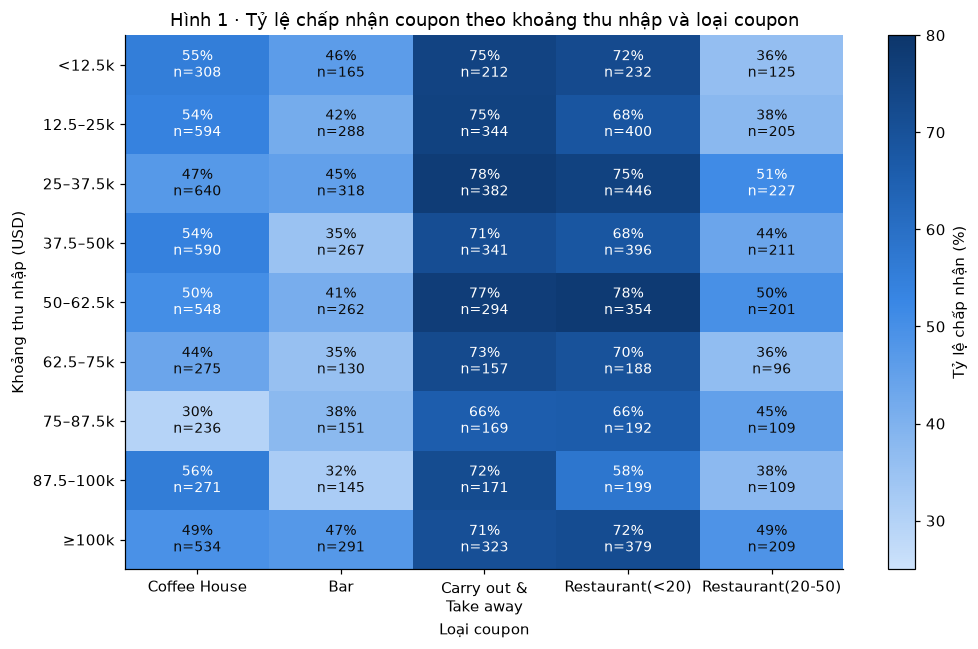

In [17]:
from matplotlib.colors import LinearSegmentedColormap

# Bảng màu dùng chung
INK = "#0b0b0b"          # màu chữ chính
MUTED = "#52514e"        # màu chữ phụ, đường tham chiếu
BLUE, ORANGE = "#2a78d6", "#eb6834"
AGE_COLORS = ["#86b6ef", "#3987e5", "#1c5cab", "#0d366b"]   # một tông xanh, nhạt -> đậm theo thứ tự tuổi
SEQ_BLUE = LinearSegmentedColormap.from_list("seq_blue", ["#cde2fb", "#86b6ef", "#3987e5", "#1c5cab", "#0d366b"])
COUPON_LABELS = [name.replace(" & ", " &\n") for name in COUPON_ORDER]   # xuống dòng cho nhãn dài

# Hình 1: heatmap thu nhập (9 khoảng gốc) × coupon, có n trong từng ô
rate_ic, n_ic = rate_and_n_by_coupon(q5, "income")

fig, ax = plt.subplots(figsize=(9.5, 6))
image = ax.imshow(rate_ic.to_numpy(), cmap=SEQ_BLUE, vmin=25, vmax=80, aspect="auto")
ax.grid(False)
for i in range(rate_ic.shape[0]):
    for j in range(rate_ic.shape[1]):
        value = rate_ic.iloc[i, j]
        text_color = "white" if value >= 50 else INK      # chữ trắng trên ô đậm để dễ đọc
        ax.text(j, i, f"{value:.0f}%\nn={n_ic.iloc[i, j]}", ha="center", va="center", fontsize=9, color=text_color)
ax.set_xticks(range(len(COUPON_ORDER)), COUPON_LABELS)
ax.set_yticks(range(len(INCOME_SHORT)), INCOME_SHORT)
ax.set_xlabel("Loại coupon")
ax.set_ylabel("Khoảng thu nhập (USD)")
ax.set_title("Hình 1 · Tỷ lệ chấp nhận coupon theo khoảng thu nhập và loại coupon")
fig.colorbar(image, ax=ax, label="Tỷ lệ chấp nhận (%)")
fig.tight_layout()
fig.savefig(FIG_DIR / "q5_fig1_income_coupon_heatmap.png", dpi=150)
plt.show()

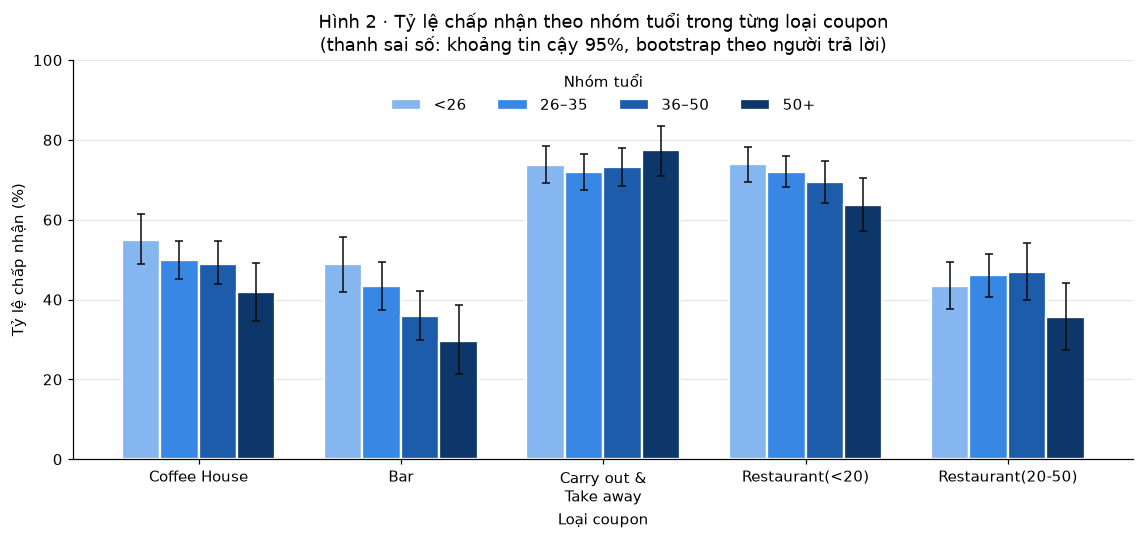

In [18]:
# Hình 2: tỷ lệ chấp nhận theo nhóm tuổi trong từng loại coupon, kèm CI 95% (bootstrap theo người)
fig, ax = plt.subplots(figsize=(10.5, 5))
bar_width = 0.19
x = np.arange(len(COUPON_ORDER))

for k, age_group in enumerate(AGE_GROUPS):
    rate = np.array([age_coupon_ci[c].loc[age_group, "ty_le_pct"] for c in COUPON_ORDER])
    low = np.array([age_coupon_ci[c].loc[age_group, "ci_low"] for c in COUPON_ORDER])
    high = np.array([age_coupon_ci[c].loc[age_group, "ci_high"] for c in COUPON_ORDER])
    position = x + (k - 1.5) * bar_width                     # 4 cột nằm cân quanh mỗi vị trí coupon
    ax.bar(position, rate, width=bar_width, color=AGE_COLORS[k], edgecolor="white", linewidth=1.5, label=age_group)
    ax.errorbar(position, rate, yerr=[rate - low, high - rate], fmt="none", ecolor=INK, elinewidth=1, capsize=2.5)

ax.set_xticks(x, COUPON_LABELS)
ax.set_ylim(0, 100)
ax.set_xlabel("Loại coupon")
ax.set_ylabel("Tỷ lệ chấp nhận (%)")
ax.set_title("Hình 2 · Tỷ lệ chấp nhận theo nhóm tuổi trong từng loại coupon\n(thanh sai số: khoảng tin cậy 95%, bootstrap theo người trả lời)")
ax.legend(title="Nhóm tuổi", ncol=4, loc="upper center", frameon=False)
ax.grid(axis="x", visible=False)
fig.tight_layout()
fig.savefig(FIG_DIR / "q5_fig2_age_group_by_coupon.png", dpi=150)
plt.show()

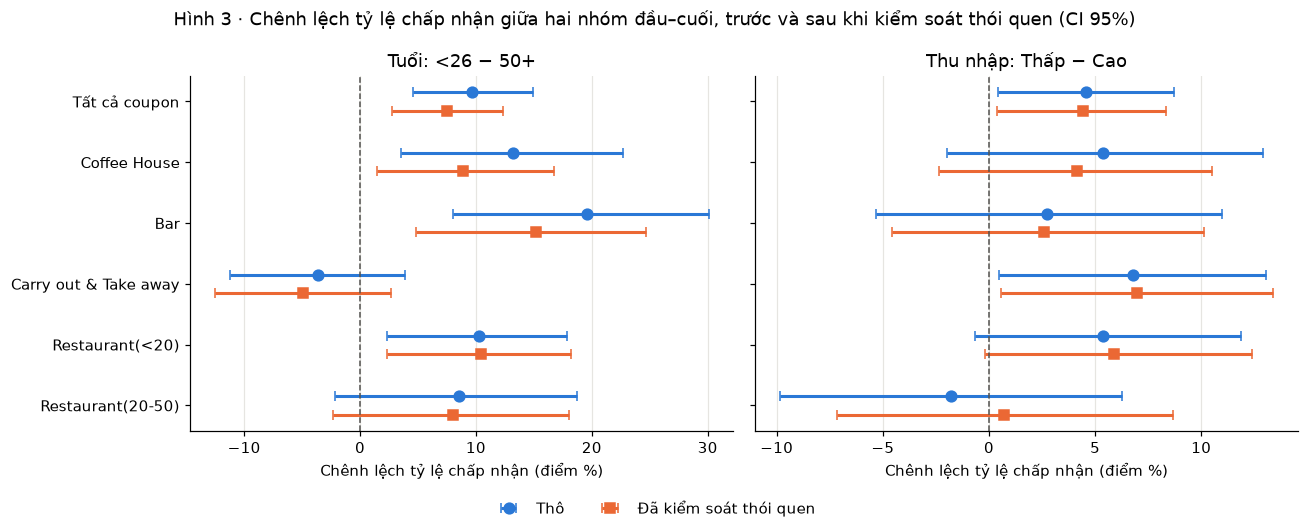

In [19]:
# Hình 3: chênh lệch giữa hai nhóm đầu–cuối, thô và sau khi kiểm soát thói quen
SCOPES = ["Tất cả coupon"] + COUPON_ORDER
# Với "Tất cả coupon" lấy mức chuẩn hoá coupon × thói quen; trong từng coupon lấy mức chuẩn hoá theo thói quen
ADJUSTED_NAMES = ["Chuẩn hoá theo coupon × thói quen", "Chuẩn hoá theo thói quen"]
SERIES = [("Thô", BLUE, "o", -0.15), ("Đã kiểm soát thói quen", ORANGE, "s", 0.15)]

fig, axes = plt.subplots(1, 2, figsize=(12, 4.8), sharey=True)
for ax, contrast_name in zip(axes, CONTRASTS):
    part = contrasts[contrasts["so_sanh"] == contrast_name]
    for series_name, color, marker, offset in SERIES:
        if series_name == "Thô":
            selected = part[part["dieu_chinh"] == "Thô"]
        else:
            selected = part[part["dieu_chinh"].isin(ADJUSTED_NAMES)]
        selected = selected.set_index("pham_vi").loc[SCOPES]
        y_pos = np.arange(len(SCOPES)) + offset
        diff = selected["chenh_lech_pp"].to_numpy()
        ax.errorbar(diff, y_pos,
                    xerr=[diff - selected["ci_low"].to_numpy(), selected["ci_high"].to_numpy() - diff],
                    fmt=marker, color=color, markersize=7, elinewidth=2, capsize=3, label=series_name)
    ax.axvline(0, color=MUTED, linewidth=1, linestyle="--")   # mốc "không chênh lệch"
    ax.set_title(contrast_name)
    ax.set_xlabel("Chênh lệch tỷ lệ chấp nhận (điểm %)")
    ax.grid(axis="y", visible=False)

axes[0].set_yticks(np.arange(len(SCOPES)), SCOPES)
axes[0].invert_yaxis()                                        # "Tất cả coupon" nằm trên cùng
handles, labels = axes[0].get_legend_handles_labels()
fig.legend(handles, labels, loc="lower center", ncol=2, frameon=False)
fig.suptitle("Hình 3 · Chênh lệch tỷ lệ chấp nhận giữa hai nhóm đầu–cuối, trước và sau khi kiểm soát thói quen (CI 95%)")
fig.tight_layout(rect=(0, 0.06, 1, 1))                        # chừa chỗ phía dưới cho chú giải
fig.savefig(FIG_DIR / "q5_fig3_contrasts_raw_vs_adjusted.png", dpi=150)
plt.show()

,ty_le_pct,ci_low,ci_high
below21,63.4,56.2,70.8
21,59.8,56.4,63.1
26,59.6,55.7,63.3
31,54.6,50.3,58.9
36,53.5,47.2,60.0
41,57.3,52.2,62.8
46,57.6,53.1,62.3
50plus,50.9,46.5,54.9


,ty_le_pct,ci_low,ci_high
Less than $12500,59.3,54.5,64.2
$12500 - $24999,57.5,53.1,62.0
$25000 - $37499,59.3,55.2,63.6
$37500 - $49999,56.4,52.2,60.8
$50000 - $62499,59.6,55.7,63.6
$62500 - $74999,52.7,45.0,60.2
$75000 - $87499,48.3,41.9,54.7
$87500 - $99999,53.2,45.3,60.0
$100000 or More,57.8,53.6,62.1


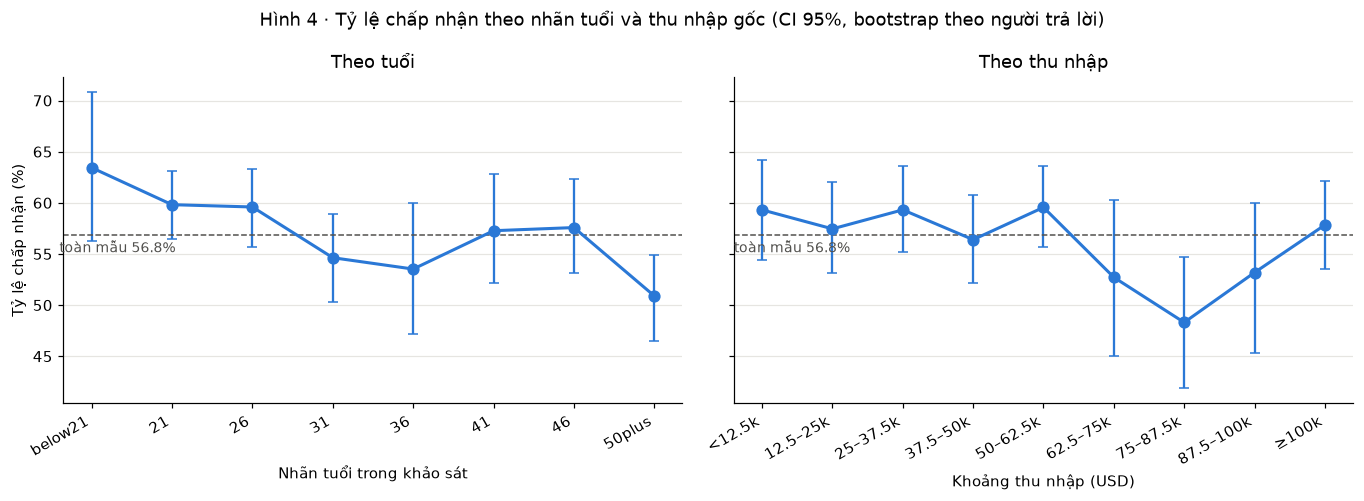

In [20]:
# Hình 4: tỷ lệ chấp nhận theo từng nhãn gốc (chưa gộp nhóm), kèm CI 95%
age_levels = rates_with_ci(q5, "age")
income_levels = rates_with_ci(q5, "income")
display(age_levels.round(1))
display(income_levels.round(1))

fig, axes = plt.subplots(1, 2, figsize=(12.5, 4.6), sharey=True)
panels = [
    (axes[0], age_levels, AGE_ORDER, "Nhãn tuổi trong khảo sát", "Theo tuổi"),
    (axes[1], income_levels, INCOME_SHORT, "Khoảng thu nhập (USD)", "Theo thu nhập"),
]
for ax, levels, labels, xlabel, title in panels:
    rate = levels["ty_le_pct"].to_numpy()
    x = np.arange(len(labels))
    ax.errorbar(x, rate, yerr=[rate - levels["ci_low"].to_numpy(), levels["ci_high"].to_numpy() - rate],
                fmt="o-", color=BLUE, markersize=7, linewidth=2, elinewidth=1.5, capsize=3)
    ax.axhline(overall_rate, color=MUTED, linewidth=1, linestyle="--")
    ax.text(-0.4, overall_rate - 0.5, f"toàn mẫu {overall_rate:.1f}%", ha="left", va="top", color=MUTED, fontsize=9)
    ax.set_xticks(x, labels, rotation=30, ha="right")
    ax.set_xlabel(xlabel)
    ax.set_title(title)
    ax.grid(axis="x", visible=False)

axes[0].set_ylabel("Tỷ lệ chấp nhận (%)")
fig.suptitle("Hình 4 · Tỷ lệ chấp nhận theo nhãn tuổi và thu nhập gốc (CI 95%, bootstrap theo người trả lời)")
fig.tight_layout()
fig.savefig(FIG_DIR / "q5_fig4_original_levels.png", dpi=150)
plt.show()

### Q5.4 · Trả lời câu hỏi và hạn chế

Mọi con số dưới đây lấy từ các bảng và hình ở trên (12.684 dòng, 567 người trả lời giả định; các phép so sánh có kiểm soát thói quen dùng 12.520 dòng). CI là khoảng tin cậy 95%, bootstrap theo người.

#### 1. Trong cùng loại coupon, nhóm tuổi và thu nhập nào chấp nhận nhiều/ít?

**Tuổi.** Tính thô, tỷ lệ chấp nhận giảm dần theo tuổi: `<26` là **60,4%** (n = 3.200; 143 người; CI 57,5–63,3), `26–35` là 57,4%, `36–50` là 55,7% và `50+` là **50,9%** (n = 1.788; 84 người; CI 46,5–54,9). Khi tách theo loại coupon thì hình ảnh không đồng đều (Hình 2):

| Coupon | `<26` | `50+` | Chênh lệch `<26 − 50+` (CI 95%) |
|---|---:|---:|---:|
| Bar | 49,1% | 29,5% | **+19,6 điểm %** (8,0 đến 30,1) |
| Coffee House | 54,9% | 41,7% | **+13,2** (3,6 đến 22,6) |
| Restaurant(<20) | 73,9% | 63,6% | **+10,3** (2,3 đến 17,9) |
| Restaurant(20-50) | 44,2% | 35,6% | +8,6 (−2,1 đến 18,8) |
| Carry out & Take away | 73,5% | 77,1% | −3,7 (−11,2 đến 3,9) |

(Bảng này tính trên bản 12.520 dòng để so được với phần kiểm soát thói quen bên dưới, nên có thể lệch 0,1–0,2 điểm % so với bảng mức 2.) Khoảng cách tuổi rõ nhất ở coupon Bar và Coffee House. Với Restaurant(20-50) và Carry out, khoảng tin cậy chứa 0 nên dữ liệu chưa đủ để nói hai nhóm tuổi khác nhau.

**Thu nhập.** Chênh lệch nhỏ hơn nhiều: nhóm Thấp 58,6% (CI 55,9–61,3), Trung bình 56,9%, Cao 54,3% (CI 51,0–57,6). Trong từng loại coupon, chỉ có **Carry out & Take away** cho chênh lệch `Thấp − Cao` có CI không chứa 0: +6,8 điểm % (0,5 đến 13,1). Ở bốn loại coupon còn lại CI đều chứa 0.

#### 2. Sau khi kiểm soát loại coupon và thói quen, khác biệt còn lại thế nào?

Thói quen đủ điều kiện làm biến nhiễu cho tuổi: người trẻ đến bar và quán cà phê thường xuyên hơn (35,0% dòng coupon Bar của nhóm `<26` thuộc mức "Thường", so với 23,8% ở nhóm `50+`; với Coffee House là 54,5% so với 43,8%), và thói quen liên hệ rất mạnh với việc chấp nhận (coupon Bar: 68,8% ở người đến thường so với 29,2% ở người đến ít; Coffee House: 66,0% so với 34,6%).

| So sánh (tất cả coupon) | Thô | Chuẩn hoá theo coupon | Chuẩn hoá theo coupon × thói quen |
|---|---:|---:|---:|
| Tuổi `<26 − 50+` | +9,7 (4,5 đến 15,0) | +9,8 (4,6 đến 15,1) | **+7,5 (2,8 đến 12,4)** |
| Thu nhập `Thấp − Cao` | +4,6 (0,4 đến 8,7) | +4,4 (0,2 đến 8,6) | **+4,4 (0,4 đến 8,4)** |

- **Tuổi:** chỉ kiểm soát loại coupon thì gần như không đổi (9,7 → 9,8), vì các nhóm tuổi nhận cơ cấu coupon gần giống nhau. Kiểm soát thêm thói quen làm chênh lệch giảm từ 9,7 xuống **7,5 điểm %**, tức thói quen giải thích khoảng một phần tư khoảng cách, phần còn lại vẫn có CI nằm hoàn toàn trên 0. Ở coupon Bar, chênh lệch giảm từ 19,6 xuống 15,2; ở Coffee House từ 13,2 xuống 8,8.
- **Thu nhập:** gần như không đổi sau khi kiểm soát (4,6 → 4,4), vì tỷ lệ người đến thường gần bằng nhau giữa các nhóm thu nhập. Nhưng khi giữ cố định **nhóm tuổi** thì chênh lệch còn +3,8 điểm % với CI −0,6 đến 7,8, tức đã chứa 0: một phần khác biệt theo thu nhập thực ra phản ánh khác biệt theo tuổi (nhóm thu nhập Thấp trẻ hơn: 34,1% số dòng thuộc nhóm `<26`, so với 18,8% ở nhóm thu nhập Cao). Chiều ngược lại không xảy ra: giữ cố định thu nhập, chênh lệch theo tuổi vẫn là +10,4 (5,1 đến 15,9).

**Trả lời trực tiếp:** mối liên hệ giữa **tuổi** và tỷ lệ chấp nhận **vẫn còn** sau khi xét loại coupon và thói quen, nhưng yếu đi khoảng một phần tư và tập trung ở coupon Bar, Coffee House và Restaurant(<20). Mối liên hệ với **thu nhập** nhỏ, nằm sát ngưỡng phân biệt được với 0 và không còn rõ khi giữ cố định tuổi.

#### 3. Có ô nào quá ít mẫu không?

Có. Trong bảng `coupon × thói quen × nhóm tuổi`, **9/40 ô** có dưới 30 người, ví dụ "Restaurant(<20), đến ít, 50+" chỉ có 52 dòng từ 10 người, và "Bar, đến thường, 50+" có 67 dòng từ 19 người. Với thu nhập là 3/30 ô. Vì vậy các CI trong từng coupon rộng tới ±8–11 điểm %, và không nên đọc từng ô riêng lẻ của bảng 3 chiều như một kết luận.

#### 4. Đổi cách gộp nhóm có làm đổi kết luận không? (D6)

- **Tuổi – chiều hướng bền, độ lớn thì không.** Cả ba cách gộp đều cho người trẻ chấp nhận nhiều hơn, nhưng độ lớn phụ thuộc vào việc so hai đầu mút xa hay gần: +9,7 (`<26 − 50+`), +6,0 (`<31 − 41+`), +4,7 (`<36 − 36+`). Sau khi kiểm soát coupon × thói quen còn +7,5, +4,0 (0,5 đến 7,3) và +3,2 (−0,1 đến 6,5); cách chia đôi thô nhất cho CI vừa chạm 0.
- **Ngưỡng thói quen có ảnh hưởng.** Nếu coi "đến thường" là ≥4 lần/tháng thay vì ≥1 lần/tháng, chênh lệch theo tuổi sau kiểm soát là +9,8, tức không giảm so với thô (45/2.000 lần lặp bootstrap của phương án này gặp ô rỗng vì có ô chỉ còn 4–5 người). Lý do là ngưỡng này gộp nhóm `1~3` lần/tháng chung với người gần như không đến, nên biến thói quen mất phần lớn khả năng phân biệt. Kết luận "thói quen giải thích một phần khoảng cách tuổi" vì thế phụ thuộc vào ngưỡng ≥1 lần/tháng.
- **Thu nhập – kết luận mong manh.** Hai cách chia ba nhóm cho +4,6 và +4,4 với cận dưới CI chỉ 0,4 và 0,1; cách chia đôi tại 50k cho +2,7 với CI −0,6 đến 6,1 (chứa 0).
- **Đơn vị bootstrap.** Nếu rút lại theo dòng, CI của chênh lệch tuổi là 6,7 đến 12,6; rút theo người là 4,5 đến 15,0, rộng hơn khoảng 1,8 lần. Coi mỗi dòng là một quan sát độc lập sẽ làm kết quả trông chắc chắn hơn thực tế.

#### Ý nghĩa thực tế

Nếu phải chọn một tiêu chí để nhắm coupon Bar hoặc Coffee House thì **thói quen** phân biệt tốt hơn hẳn tuổi (chênh 31–40 điểm % giữa người đến thường và người đến ít, so với 13–20 điểm % giữa nhóm trẻ nhất và già nhất). Tuổi vẫn mang thêm thông tin sau khi đã biết thói quen, nên có thể dùng làm tiêu chí phụ cho hai loại coupon này. Thu nhập không nên là tiêu chí nhắm chính: khác biệt nhỏ và không ổn định. Đây là gợi ý có điều kiện, vì dữ liệu là ý định trong khảo sát chứ không phải hành vi đổi coupon thật.

#### Điều bất ngờ

1. **Thu nhập không tuyến tính** (Hình 4). Tỷ lệ thấp nhất nằm ở khoảng 75–87,5k (48,3%; CI 41,9–54,7), còn nhóm từ 100k trở lên lại ở 57,8% (CI 53,6–62,1), cao hơn mức toàn mẫu 56,8%. Giả thuyết "thu nhập càng cao càng ít nhận coupon" không được dữ liệu ủng hộ.
2. **Khoảng cách tuổi biến mất ở người hay đi bar.** Trong nhóm đến bar thường xuyên, `<26` và `50+` chấp nhận coupon Bar gần như bằng nhau (67,0% và 67,2%); khoảng cách nằm gần hết ở nhóm đến ít (39,4% so với 17,8%). Ô "đến thường, 50+" chỉ có 19 người nên đây mới là gợi ý, chưa phải kết luận.
3. **Carry out & Take away đi ngược chiều:** nhóm `50+` chấp nhận nhiều hơn nhóm `<26` (77,1% so với 73,5%), dù CI chứa 0.

#### Hạn chế

- `Y` là ý định trong kịch bản giả định; người trả lời đến từ Amazon Mechanical Turk nên không đại diện cho mọi tài xế.
- `respondent_id` được suy ra từ hồ sơ trùng nhau, không phải ID thật: hai người có hồ sơ giống hệt bị gộp làm một.
- Thói quen chỉ được chia hai mức và do người trả lời tự khai, nên vẫn còn nhiễu chưa kiểm soát hết (residual confounding); các biến khác như nghề nghiệp, hôn nhân chưa được xét.
- Nhiều phép so sánh được thực hiện cùng lúc (2 biến × 6 phạm vi × nhiều mức điều chỉnh). Với ngưỡng 95%, một vài CI không chứa 0 có thể chỉ do ngẫu nhiên, đặc biệt các CI có cận dưới sát 0 như của thu nhập.
- Nhãn tuổi là khoảng 5 năm và `50plus` không có cận trên; thu nhập là khoảng tiền. Mọi kết luận ở mức nhóm, không ở mức từng tuổi hay từng mức thu nhập.
- Đây là mối liên hệ quan sát được trong khảo sát, không cho phép nói tuổi hay thu nhập *gây ra* việc chấp nhận coupon.